#Section 1 – Introduction to Logistic Regression

In [67]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

from sklearn.datasets import load_breast_cancer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)
from sklearn.preprocessing import StandardScaler

In [68]:
#create simple toy datasets
hours_studied = np.array([1, 2, 3, 4, 5, 6, 7, 8, 9]).reshape(-1, 1)
pass_exam = np.array([0, 0, 0, 0, 1, 1, 1, 1, 1])

toy_df= pd.DataFrame({
    'hours_studied':hours_studied.flatten(),
    'pass_exam':pass_exam
})
toy_df

,hours_studied,pass_exam
0,1,0
1,2,0
2,3,0
3,4,0
4,5,1
5,6,1
6,7,1
7,8,1
8,9,1


In [69]:
#model train and cof show
toy_model=LogisticRegression()
toy_model.fit(hours_studied,pass_exam)
print("Intercept (b):", toy_model.intercept_)
print("Coefficient (w):", toy_model.coef_)

Intercept (b): [-5.29559243]
Coefficient (w): [[1.17808562]]


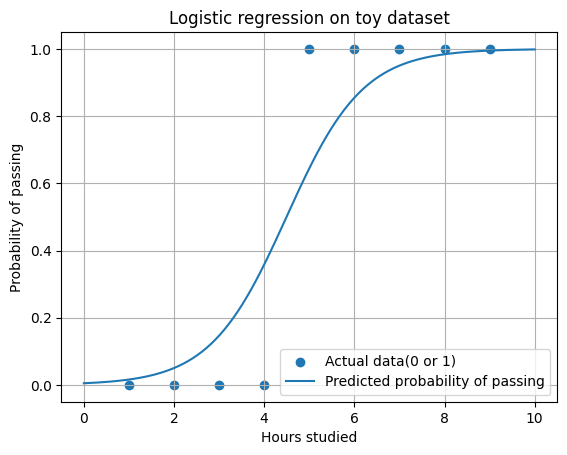

In [70]:
# Predict probabilities for a range of study hours
hours_grid=np.linspace(0,10,200).reshape(-1,1)
pass_proba=toy_model.predict_proba(hours_grid)[:,1]

plt.figure()
plt.scatter(hours_studied,pass_exam, label= 'Actual data(0 or 1)')
plt.plot(hours_grid, pass_proba, label="Predicted probability of passing")
plt.xlabel("Hours studied")
plt.ylabel("Probability of passing")
plt.title("Logistic regression on toy dataset")
plt.legend()
plt.grid(True)
plt.show()

In [71]:
#few example  students
example_hours=np.array([[2], [4], [6], [8]])
example_prob=toy_model.predict_proba(example_hours)[:,1]
example_pred=toy_model.predict(example_hours)

example_df= pd.DataFrame({
    'Studied_hours':example_hours.flatten(),
    'Pass Predicted_probability':np.round(example_prob, 4),
    'Predicted_class':example_pred
})
example_df

,Studied_hours,Pass Predicted_probability,Predicted_class
0,2,0.0502,0
1,4,0.3582,0
2,6,0.8548,1
3,8,0.9842,1


#Section 2 – Sigmoid Function and Classification Intuition

In [72]:
#sigmid finction
def sigmoid(z):
 return 1/(1+np.exp(-z))

#check some values
z_values=np.array([-5,-2,-1,0,1,2,5],dtype=float)
sig_values= sigmoid(z_values)

sig_df=pd.DataFrame({
    'z':z_values,
    'sigmoid(z)':np.round(sig_values,4)
})
sig_df

,z,sigmoid(z)
0,-5.0,0.0067
1,-2.0,0.1192
2,-1.0,0.2689
3,0.0,0.5000
4,1.0,0.7311
5,2.0,0.8808
6,5.0,0.9933


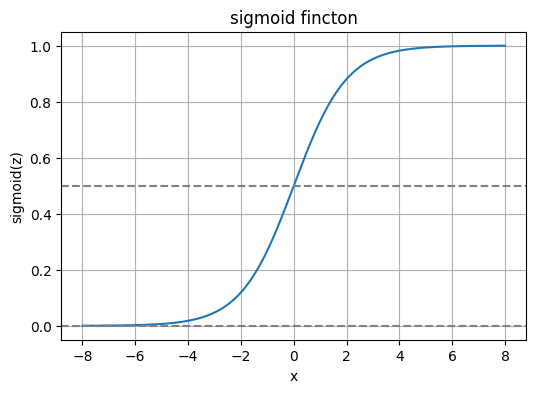

In [73]:
#plot the sigmid curve
z_grid = np.linspace(-8, 8, 400)
sig_grid= sigmoid(z_grid)

plt.figure(figsize=(6,4))
plt.plot(z_grid, sig_grid)
plt.xlabel('x')
plt.ylabel('sigmoid(z)')
plt.title('sigmoid fincton')
plt.grid(True)
plt.axhline(0.5, color='gray', linestyle='--')
plt.axhline(0, color='gray', linestyle='--')

In [74]:
#simple threshold demonstration
probabilities=np.array([0.1, 0.3, 0.49, 0.5, 0.7, 0.9])
threshold= 0.25
pred_class= (probabilities >=threshold).astype(int)

thresh_df= pd.DataFrame({
    "probability": probabilities,
    "class_at_threshold_0.5": pred_class
})

thresh_df

,probability,class_at_threshold_0.5
0,0.10,0
1,0.30,1
2,0.49,1
3,0.50,1
4,0.70,1
5,0.90,1
